In [27]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# collecting data

In [28]:
base_dir = Path.cwd().resolve().parent
data = base_dir / "data"
raw = data / "raw"
output = base_dir / "outputs"

df_train = pd.read_csv(raw / "train.csv")

print(df_train.columns)

Index(['id', 'person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'loan_status'],
      dtype='str')


In [29]:
# drop unnecessary ID column
if 'id' in df_train.columns : df_train.drop(['id'], axis=1, inplace=True)

# inspecting

In [30]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  58645 non-null  int64  
 1   person_income               58645 non-null  int64  
 2   person_home_ownership       58645 non-null  str    
 3   person_emp_length           58645 non-null  float64
 4   loan_intent                 58645 non-null  str    
 5   loan_grade                  58645 non-null  str    
 6   loan_amnt                   58645 non-null  int64  
 7   loan_int_rate               58645 non-null  float64
 8   loan_percent_income         58645 non-null  float64
 9   cb_person_default_on_file   58645 non-null  str    
 10  cb_person_cred_hist_length  58645 non-null  int64  
 11  loan_status                 58645 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 6.4 MB


In [31]:
print(df_train.head(5))

   person_age  person_income person_home_ownership  person_emp_length  \
0          37          35000                  RENT                0.0   
1          22          56000                   OWN                6.0   
2          29          28800                   OWN                8.0   
3          30          70000                  RENT               14.0   
4          22          60000                  RENT                2.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_percent_income  \
0   EDUCATION          B       6000          11.49                 0.17   
1     MEDICAL          C       4000          13.35                 0.07   
2    PERSONAL          A       6000           8.90                 0.21   
3     VENTURE          B      12000          11.11                 0.17   
4     MEDICAL          A       6000           6.92                 0.10   

  cb_person_default_on_file  cb_person_cred_hist_length  loan_status  
0                         N            

In [32]:
print(df_train.dtypes)

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
loan_status                     int64
dtype: object


In [33]:
df_train.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
count,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


In [34]:
print(df_train.isnull().sum())
print(df_train['loan_status'].value_counts(normalize=True) * 100)

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64
loan_status
0    85.761787
1    14.238213
Name: proportion, dtype: float64


In [35]:
print("person_home_ownership type: " , df_train['person_home_ownership'].unique())
print("loan_intent type: " , df_train['loan_intent'].unique())
print("loan_grade type: " , df_train['loan_grade'].unique())
print("cb_person_default_on_file type: " , df_train['cb_person_default_on_file'].unique())

person_home_ownership type:  <ArrowStringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
loan_intent type:  <ArrowStringArray>
[        'EDUCATION',           'MEDICAL',          'PERSONAL',
           'VENTURE', 'DEBTCONSOLIDATION',   'HOMEIMPROVEMENT']
Length: 6, dtype: str
loan_grade type:  <ArrowStringArray>
['B', 'C', 'A', 'D', 'E', 'F', 'G']
Length: 7, dtype: str
cb_person_default_on_file type:  <ArrowStringArray>
['N', 'Y']
Length: 2, dtype: str


In [36]:
if "person_age" in df_train.columns:
    print("Age below 18:",
          (df_train["person_age"] < 18).sum())
    print("Age above 100:",
          (df_train["person_age"] > 100).sum())

if "person_emp_length" in df_train.columns:
    print("Negative employment length:",
          (df_train["person_emp_length"] < 0).sum())
    print("Employment longer than age:",
          (df_train["person_emp_length"] >
           df_train["person_age"]).sum())

if "person_income" in df_train.columns:
    print("Non-positive income:",
          (df_train["person_income"] <= 0).sum())

if "loan_amnt" in df_train.columns:
    print("Non-positive loan amount:",
          (df_train["loan_amnt"] <= 0).sum())

if "loan_int_rate" in df_train.columns:
    print("Non-positive interest rate:",
          (df_train["loan_int_rate"] <= 0).sum())

Age below 18: 0
Age above 100: 1
Negative employment length: 0
Employment longer than age: 2
Non-positive income: 0
Non-positive loan amount: 0
Non-positive interest rate: 0


# EDA

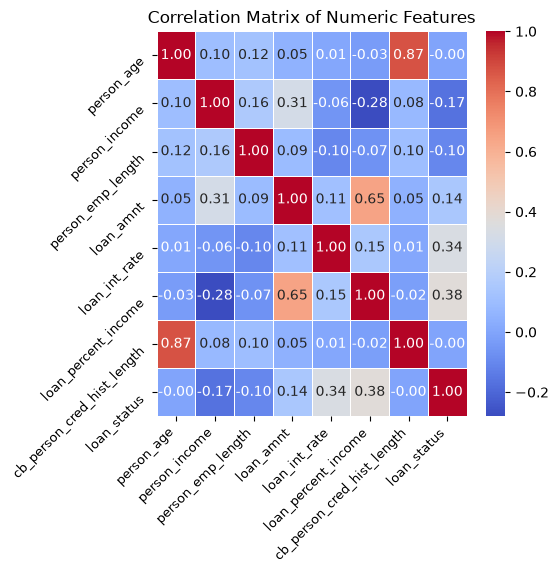

In [37]:
plt.figure(figsize=(5, 5))
numeric_cols = df_train.select_dtypes(include=['int64', 'Float64']).columns
correlation = df_train[numeric_cols].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.yticks(rotation=45, va='top', fontsize=9)
plt.xticks(rotation=45,ha='right', fontsize=9)

plt.title("Correlation Matrix of Numeric Features")
plt.savefig(fname= output / "correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

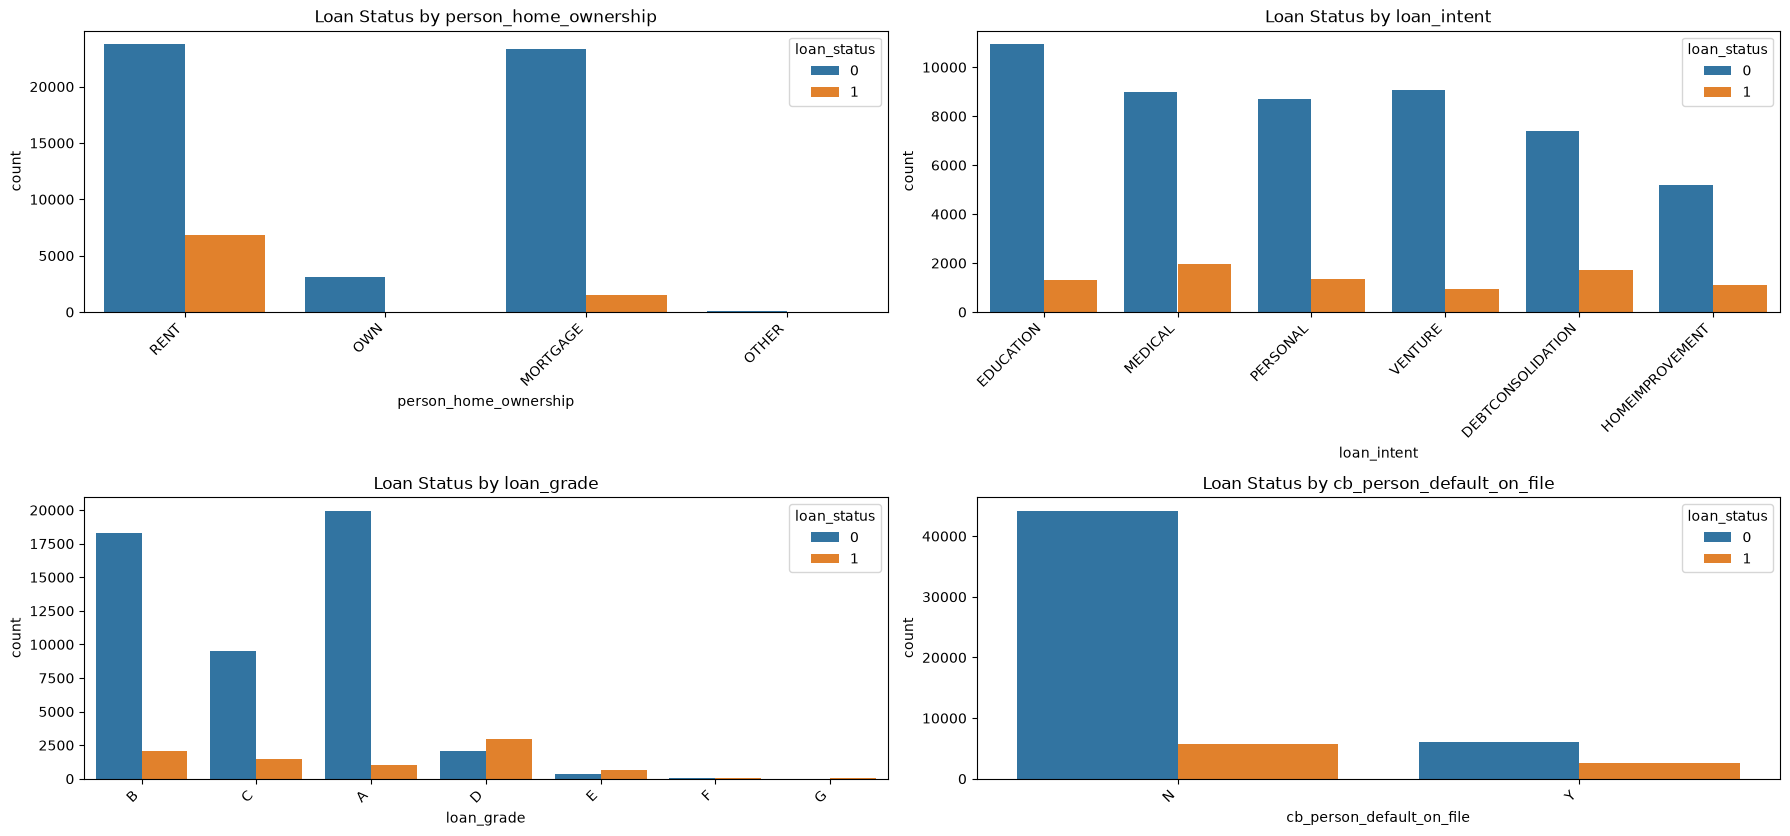

In [38]:
categorical_cols = df_train.select_dtypes(include=['str']).columns
index = 1
plt.figure(figsize=(18,36))
for col in categorical_cols:
    plt.subplot(8,2, index)
    sns.countplot(data=df_train,x=col, hue='loan_status')
    plt.title(f"Loan Status by {col}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    index+=1
plt.savefig(output / f"categorical.png", dpi=300, bbox_inches='tight')
plt.show()
    

In [39]:
print(df_train["person_age"].describe())
print(df_train["person_income"].describe())
print(df_train["loan_amnt"].describe())
print(df_train["person_emp_length"].describe())

count    58645.000000
mean        27.550857
std          6.033216
min         20.000000
25%         23.000000
50%         26.000000
75%         30.000000
max        123.000000
Name: person_age, dtype: float64
count    5.864500e+04
mean     6.404617e+04
std      3.793111e+04
min      4.200000e+03
25%      4.200000e+04
50%      5.800000e+04
75%      7.560000e+04
max      1.900000e+06
Name: person_income, dtype: float64
count    58645.000000
mean      9217.556518
std       5563.807384
min        500.000000
25%       5000.000000
50%       8000.000000
75%      12000.000000
max      35000.000000
Name: loan_amnt, dtype: float64
count    58645.000000
mean         4.701015
std          3.959784
min          0.000000
25%          2.000000
50%          4.000000
75%          7.000000
max        123.000000
Name: person_emp_length, dtype: float64


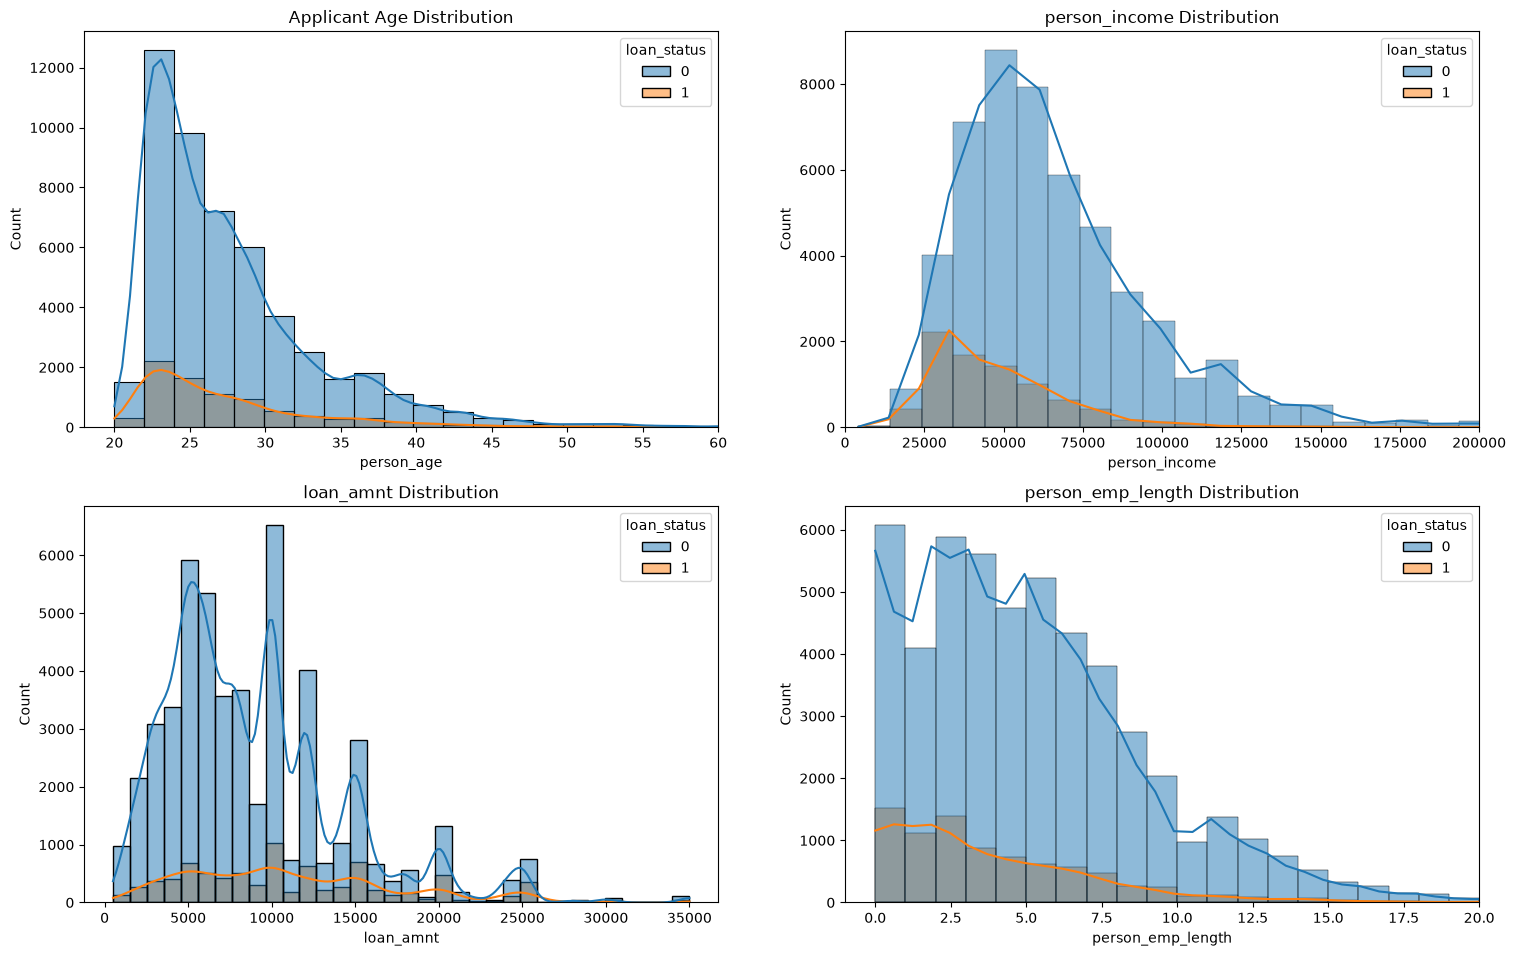

In [40]:
index = 1
plt.figure(figsize=(18,36))
plt.subplot(6,2, index)
sns.histplot(data=df_train, x='person_age', binwidth=2, kde=True, hue="loan_status",)
plt.xlim(18, 60)
plt.title(f"Applicant Age Distribution")
index+=1

plt.subplot(6,2, index)
sns.histplot(data=df_train, x='person_income',binwidth=1e4, kde=True, hue="loan_status",)
plt.xlim(0.0e6, 0.2e6)
plt.title(f"person_income Distribution")
index+=1

plt.subplot(6,2, index)
sns.histplot(data=df_train, x='loan_amnt',binwidth=1e3, kde=True, hue="loan_status",)
plt.title(f"loan_amnt Distribution")
index+=1

plt.subplot(6,2, index)
sns.histplot(data=df_train, x='person_emp_length',binwidth=1, kde=True, hue="loan_status",)
plt.xlim(-1, 20)
plt.title(f"person_emp_length Distribution")
index+=1

plt.savefig(output / f"histplot.png", dpi=300, bbox_inches='tight')
plt.show()

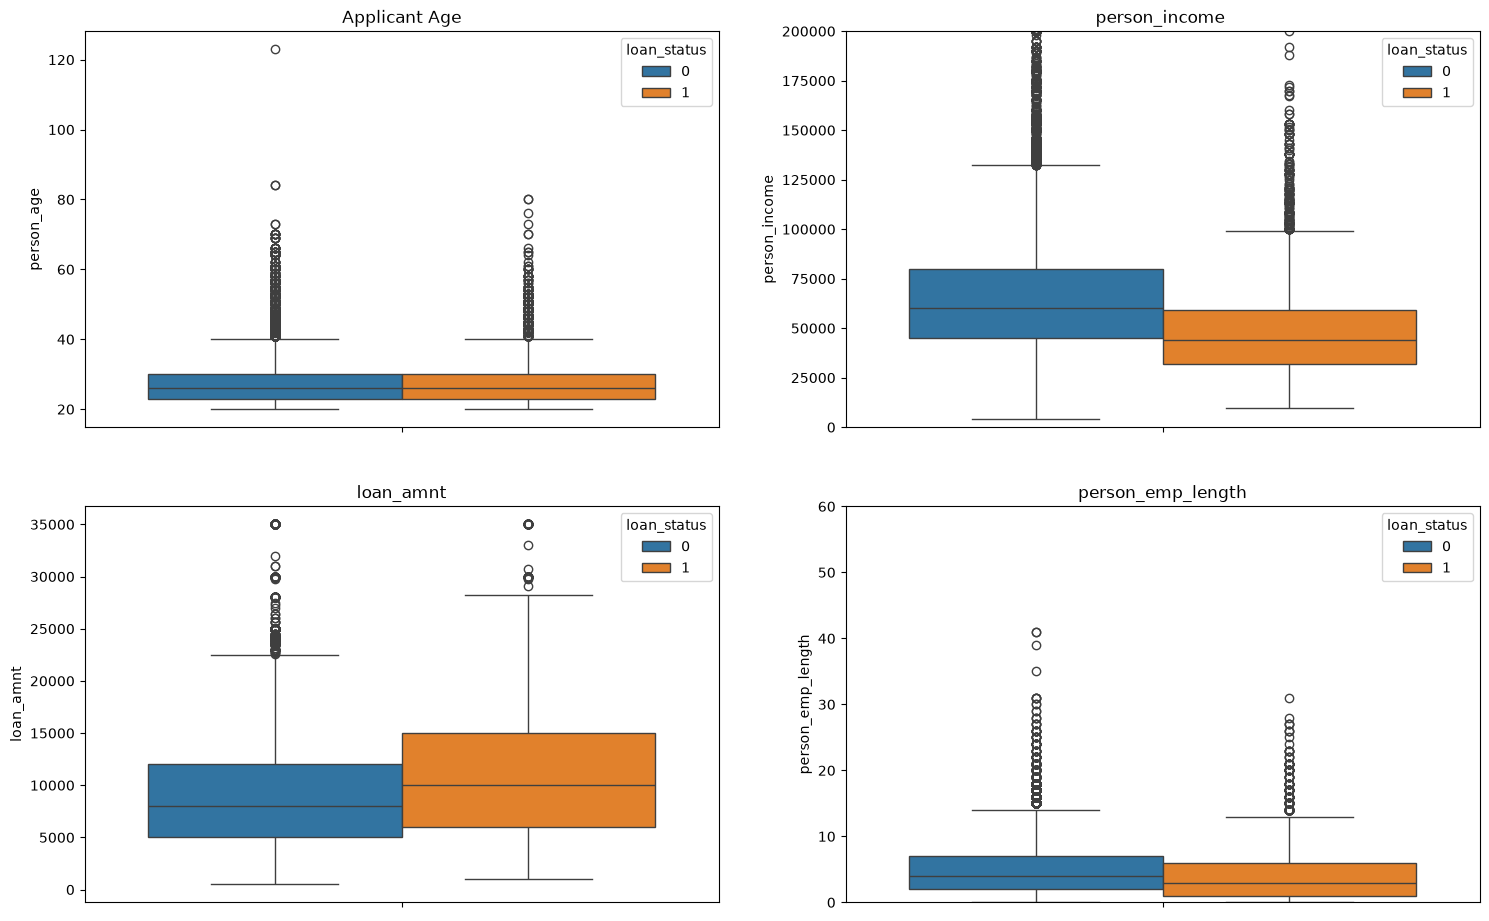

In [41]:
index = 1
plt.figure(figsize=(18,36))
plt.subplot(6,2, index)
sns.boxplot(data=df_train, y='person_age', hue="loan_status",)
# plt.xlim(18, 60)
plt.title(f"Applicant Age")
index+=1

plt.subplot(6,2, index)
sns.boxplot(data=df_train, y='person_income', hue="loan_status",)
plt.ylim(0.0e6, 0.2e6)
plt.title(f"person_income ")
index+=1

plt.subplot(6,2, index)
sns.boxplot(data=df_train, y='loan_amnt', hue="loan_status",)
plt.title(f"loan_amnt")
index+=1

plt.subplot(6,2, index)
sns.boxplot(data=df_train, y='person_emp_length', hue="loan_status",)
plt.ylim(0, 60)
plt.title(f"person_emp_length")
index+=1

plt.savefig(output / f"boxplot.png", dpi=300, bbox_inches='tight')
plt.show()